# Phenotypic Diversity, Trait Associations, and Machine Learning Evaluation of Ghanaian Cowpea (*Vigna unguiculata*) Accessions

**Portfolio Project | Computational Agronomy & Applied Data Science**  
**Author:** Abinumar  
**Data Source:** [Genesys Plant Genetic Resources Database](https://www.genesys-pgr.org) (CSIR - Plant Genetic Resources Research Institute, Bunso, Ghana; `INSTCODE: GHA091`)

---

## 1. Project Overview & Scientific Context

Cowpea (*Vigna unguiculata* [L.] Walp.) is an indispensable indigenous legume crop cultivated across the semi-arid tropics of sub-Saharan Africa. Renowned as "poor man's meat", it provides high-protein dietary grain (23–25% protein content), nutrient-dense fodder for livestock, and ecological benefits through symbiotic atmospheric nitrogen fixation.

Despite its importance, cowpea yields in West Africa often remain below potential due to biotic and abiotic stresses. Effective germplasm characterization is the foundational cornerstone of crop improvement and breeding programs.

### Research Objectives:
1. **Phenotypic Diversity Profiling:** Quantify the richness and evenness of qualitative agro-morphological traits across the accession collection using **Shannon-Weaver ($H'$)** and **Simpson** diversity indices.
2. **Agronomic Trade-Offs & Trait Stratification:** Investigate relationships between primary yield components (100-seed weight, pod length, pod count) and determine how growth habit moderates these relationships.
3. **Comprehensive Mixed-Data Association Architecture:** Construct a mathematically rigorous multi-trait association matrix combining **Pearson correlation**, **Cramér's V**, and the **Correlation Ratio ($\eta$)** to resolve trait correlations across continuous and discrete descriptors.
4. **Multivariate Pattern Discovery:** Perform **Factor Analysis of Mixed Data (FAMD)** and **Hierarchical Clustering (Gower Distance)** to uncover population structure and accession groupings.
5. **Predictive Machine Learning & Generalizability Diagnostics:** Benchmark predictive models (Random Forest, Lasso, Ridge) to predict 100-seed weight, providing critical diagnostic evaluations of model overfitting and data limitations in quantitative genetics.


## 2. Environment Setup & Library Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import skbio.diversity.alpha as alpha
import gower
from prince import FAMD
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')

# Visual styling setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.titlesize'] = 15


## 3. Data Ingestion & Quality Control (Deduplication)

The dataset encompasses agro-morphological evaluation records for **92 cowpea accessions** obtained from the **Genesys Plant Genetic Resources database**, conserved by the **CSIR-PGRRI (Bunso, Ghana)**.

Before analysis, we perform strict data hygiene:
- Verify metadata consistency (`INSTCODE: GHA091`, `GENUS: Vigna`).
- Identify and eliminate exact duplicate records resulting from redundant sampling or duplicate inventory entries in the repository.


In [2]:
# Load raw dataset
data_path = "Cowpea 220125.xlsx"
df_raw = pd.read_excel(data_path)

print(f"Initial dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Unique accession IDs: {df_raw['Accession'].nunique()}")
print(f"Identical duplicate rows identified: {df_raw.duplicated().sum()}")

# Clean duplicates to ensure independent biological observations
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Cleaned dataset shape: {df.shape[0]} unique accessions, {df.shape[1]} columns")


Initial dataset shape: 92 rows, 20 columns
Unique accession IDs: 83
Identical duplicate rows identified: 9
Cleaned dataset shape: 83 unique accessions, 20 columns


In [3]:
# Inspect column types and completeness
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   INSTCODE                        83 non-null     object 
 1   Accession                       83 non-null     object 
 2   GENUS                           83 non-null     object 
 3   Vigour                          32 non-null     object 
 4   Growth habit                    83 non-null     object 
 5   Flower colour                   83 non-null     object 
 6   Plant pimentation               76 non-null     object 
 7   Immature Pod Pigmentation       19 non-null     object 
 8   MPC                             83 non-null     object 
 9   Eye colour                      83 non-null     object 
 10  Seed Coat Colour                83 non-null     object 
 11  Pod attachment                  80 non-null     object 
 12  Terminal leaflet shape          83 non

In [4]:
# Cardinality and distinct values per trait
df.nunique()


INSTCODE                           1
Accession                         83
GENUS                              1
Vigour                             2
Growth habit                       5
Flower colour                      2
Plant pimentation                  3
Immature Pod Pigmentation          4
MPC                                5
Eye colour                         4
Seed Coat Colour                   5
Pod attachment                     2
Terminal leaflet shape             4
Pod curvature                      2
Seed shape                         4
DF (Days to 50% flowering)        14
No. pods                           4
Pod Length(cm)                    26
No. SPP (No. of seeds per pod)    23
SW(g) 100 seed weight             76
dtype: int64

## 4. Exploratory Data Analysis: Agro-Morphological Distributions

### 4.1 Distribution of Primary Yield Metric: 100-Seed Weight (g)
100-seed weight (`SW(g) 100 seed weight`) is a standard agronomic metric representing seed size and density, directly influencing marketable yield and commercial seed grading.


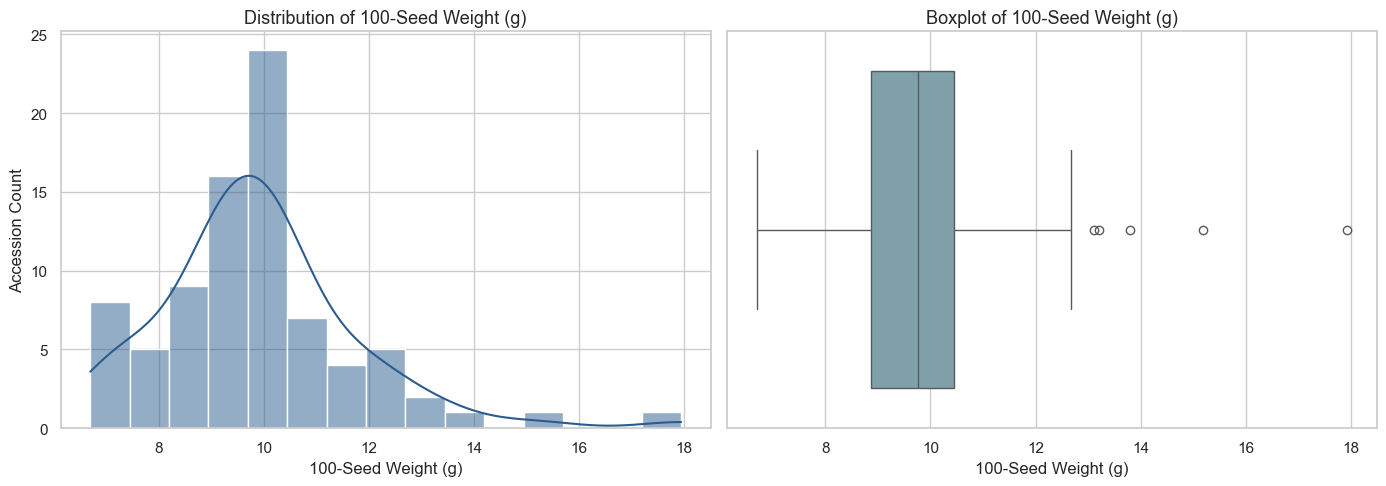

Summary Statistics for 100-Seed Weight:
count    83.000000
mean      9.892771
std       1.865789
min       6.690000
25%       8.860000
50%       9.760000
75%      10.455000
max      17.940000
Name: SW(g) 100 seed weight, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kernel Density Estimate & Histogram
sns.histplot(df["SW(g) 100 seed weight"], kde=True, ax=axes[0], color="#2b5c8f", bins=15)
axes[0].set_title("Distribution of 100-Seed Weight (g)")
axes[0].set_xlabel("100-Seed Weight (g)")
axes[0].set_ylabel("Accession Count")

# Boxplot
sns.boxplot(x=df["SW(g) 100 seed weight"], ax=axes[1], color="#79a3b1")
axes[1].set_title("Boxplot of 100-Seed Weight (g)")
axes[1].set_xlabel("100-Seed Weight (g)")

plt.tight_layout()
plt.show()

print("Summary Statistics for 100-Seed Weight:")
print(df["SW(g) 100 seed weight"].describe())


### 4.2 Distribution of Major Qualitative Categorical Traits
We examine key vegetative and reproductive morphological descriptors: Growth habit, Flower colour, and Plant vigour.


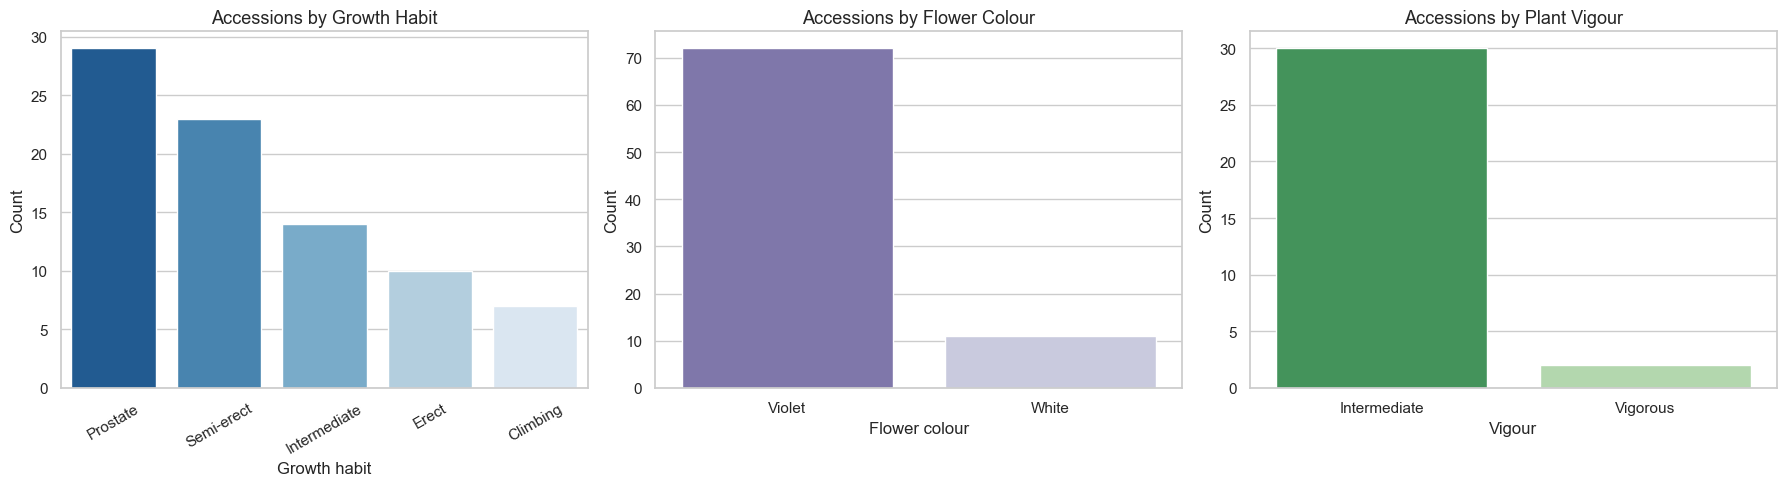

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Growth Habit
order_gh = df["Growth habit"].value_counts().index
sns.countplot(data=df, x="Growth habit", order=order_gh, ax=axes[0], palette="Blues_r")
axes[0].set_title("Accessions by Growth Habit")
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylabel("Count")

# Flower Colour
order_fc = df["Flower colour"].value_counts().index
sns.countplot(data=df, x="Flower colour", order=order_fc, ax=axes[1], palette="Purples_r")
axes[1].set_title("Accessions by Flower Colour")
axes[1].set_ylabel("Count")

# Vigour
order_vg = df["Vigour"].dropna().value_counts().index
sns.countplot(data=df, x="Vigour", order=order_vg, ax=axes[2], palette="Greens_r")
axes[2].set_title("Accessions by Plant Vigour")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()


### 4.3 Qualitative Trait Inventory & Phenotypic Modalities
We catalogue all discrete phenotypic descriptors recorded in the germplasm database.


In [7]:
qual_traits = [
    "Growth habit", "Flower colour", "Plant pimentation", 
    "Immature Pod Pigmentation", "MPC", "Eye colour", 
    "Seed Coat Colour", "Pod attachment", "Terminal leaflet shape", 
    "Pod curvature", "Seed shape", "Vigour"
]

print("=== Qualitative Phenotypic Descriptors Recorded ===")
for trait in qual_traits:
    unique_vals = list(df[trait].dropna().unique())
    print(f"- {trait} ({len(unique_vals)} phenotypes): {unique_vals}")


=== Qualitative Phenotypic Descriptors Recorded ===
- Growth habit (5 phenotypes): ['Semi-erect', 'Intermediate', 'Prostate', 'Erect', 'Climbing']
- Flower colour (2 phenotypes): ['Violet', 'White']
- Plant pimentation (3 phenotypes): ['Moderate', 'Very slight', 'Intermediate']
- Immature Pod Pigmentation (4 phenotypes): ['Straw', 'Pigmented', 'Sutures', 'Pigmented tip']
- MPC (5 phenotypes): ['Straw', 'Dark brown', 'Dark', 'Black', 'Other']
- Eye colour (4 phenotypes): ['Eye absent', 'Brown', 'Black', 'Mottled']
- Seed Coat Colour (5 phenotypes): ['Brown', 'Other', 'Black', 'Red', 'Cream']
- Pod attachment (2 phenotypes): ['30-90˚', 'Pendant']
- Terminal leaflet shape (4 phenotypes): ['Sub-hastate', 'Sub-globose', 'Hastate', 'Globose']
- Pod curvature (2 phenotypes): ['Slightly', 'Straight']
- Seed shape (4 phenotypes): ['Rhomboid', 'Ovoid', 'Kidney', 'Globose']
- Vigour (2 phenotypes): ['Intermediate', 'Vigorous']


## 5. Phenotypic Diversity Profiling (Shannon-Weaver & Simpson Indices)

To evaluate the genetic and morphological richness of the Ghanaian germplasm collection, we compute ecological diversity metrics:
- **Observed Richness ($S_{obs}$):** The number of distinct phenotypic morphotypes observed.
- **Shannon-Weaver Diversity Index ($H'$):** Measures both the richness and relative evenness of phenotypic classes:
  $$H' = -\sum_{i=1}^{S} p_i \ln(p_i)$$
- **Simpson Diversity Index ($D$):** Quantifies the probability that two randomly sampled accessions exhibit different phenotypes ($1 - \sum p_i^2$).
- **Pielou Evenness ($J'$):** Equitability of phenotypic distribution ($H' / \ln(S_{obs})$).


,Trait,Richness (S_obs),Shannon Index (H'),Simpson Index,Pielou Evenness (J')
6,Seed Coat Colour,5,1.511,0.767,0.939
0,Growth habit,5,1.487,0.751,0.924
10,Seed shape,4,1.054,0.610,0.760
3,Immature Pod Pigmentation,4,1.010,0.543,0.729
8,Terminal leaflet shape,4,1.002,0.549,0.723
2,Plant pimentation,3,0.869,0.540,0.791
4,MPC,5,0.665,0.316,0.413
7,Pod attachment,2,0.621,0.430,0.896
9,Pod curvature,2,0.523,0.340,0.754
1,Flower colour,2,0.391,0.230,0.564


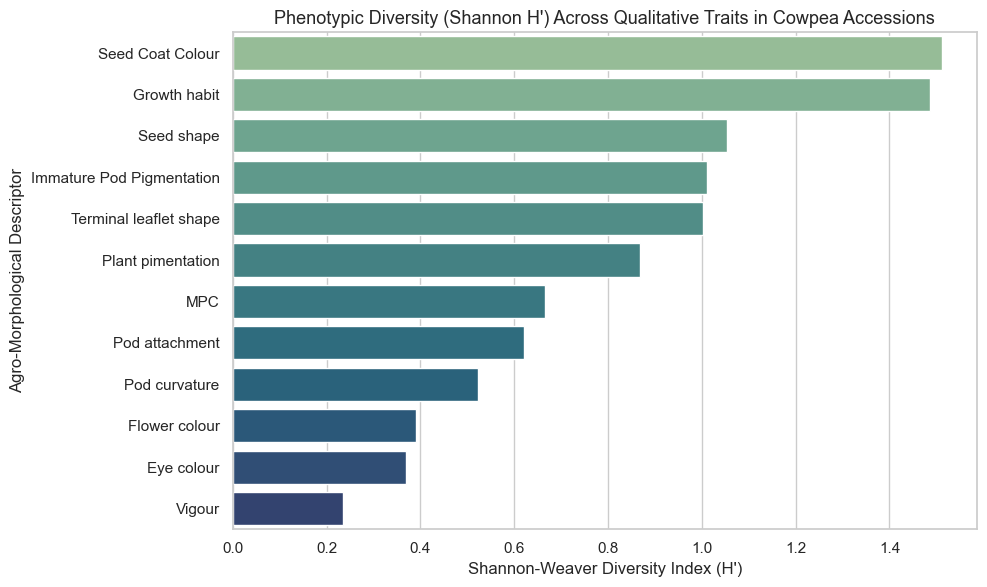

In [8]:
diversity_records = []

for trait in qual_traits:
    counts = df[trait].dropna().value_counts().values
    s_obs = alpha.sobs(counts)
    h_prime = alpha.shannon(counts)
    simpson = alpha.simpson(counts)
    evenness = h_prime / np.log(s_obs) if s_obs > 1 else 0.0
    
    diversity_records.append({
        "Trait": trait,
        "Richness (S_obs)": s_obs,
        "Shannon Index (H')": round(h_prime, 3),
        "Simpson Index": round(simpson, 3),
        "Pielou Evenness (J')": round(evenness, 3)
    })

diversity_df = pd.DataFrame(diversity_records).sort_values(by="Shannon Index (H')", ascending=False)
display(diversity_df)

# Visualization of Trait Diversity
plt.figure(figsize=(10, 6))
sns.barplot(data=diversity_df, x="Shannon Index (H')", y="Trait", palette="crest")
plt.title("Phenotypic Diversity (Shannon H') Across Qualitative Traits in Cowpea Accessions")
plt.xlabel("Shannon-Weaver Diversity Index (H')")
plt.ylabel("Agro-Morphological Descriptor")
plt.tight_layout()
plt.show()


**Agronomic Interpretation of Phenotypic Diversity:**
1. **High Diversity Traits:** `Seed Coat Colour` ($H' = 1.511$, 5 classes) and `Growth habit` ($H' = 1.487$, 5 classes) exhibit the highest diversity. This broad variation reflects extensive farmer selection for diverse culinary preferences and cropping systems (e.g., intercropping vs. sole cropping).
2. **Intermediate Diversity Traits:** `Seed shape`, `Immature Pod Pigmentation`, and `Terminal leaflet shape` display substantial polymorphism ($H' \approx 1.00$).
3. **Low Diversity / Conserved Traits:** `Vigour` ($H' = 0.234$) and `Flower colour` ($H' = 0.391$) display low diversity. Violet flowers overwhelmingly dominate (91.5% of accessions), and documented vigour is predominantly intermediate, suggesting strong ancestral conservation or selective sweeps.


## 6. Trait Interactions & Agronomic Trade-Offs

### 6.1 Quantitative Trait Relationships: Pod Characteristics vs. Seed Weight
Crop yield is a product of multiple interacting components: number of pods per plant, number of seeds per pod, and individual seed weight. In legumes, resource allocation creates distinct trade-offs between seed size and seed/pod quantity.


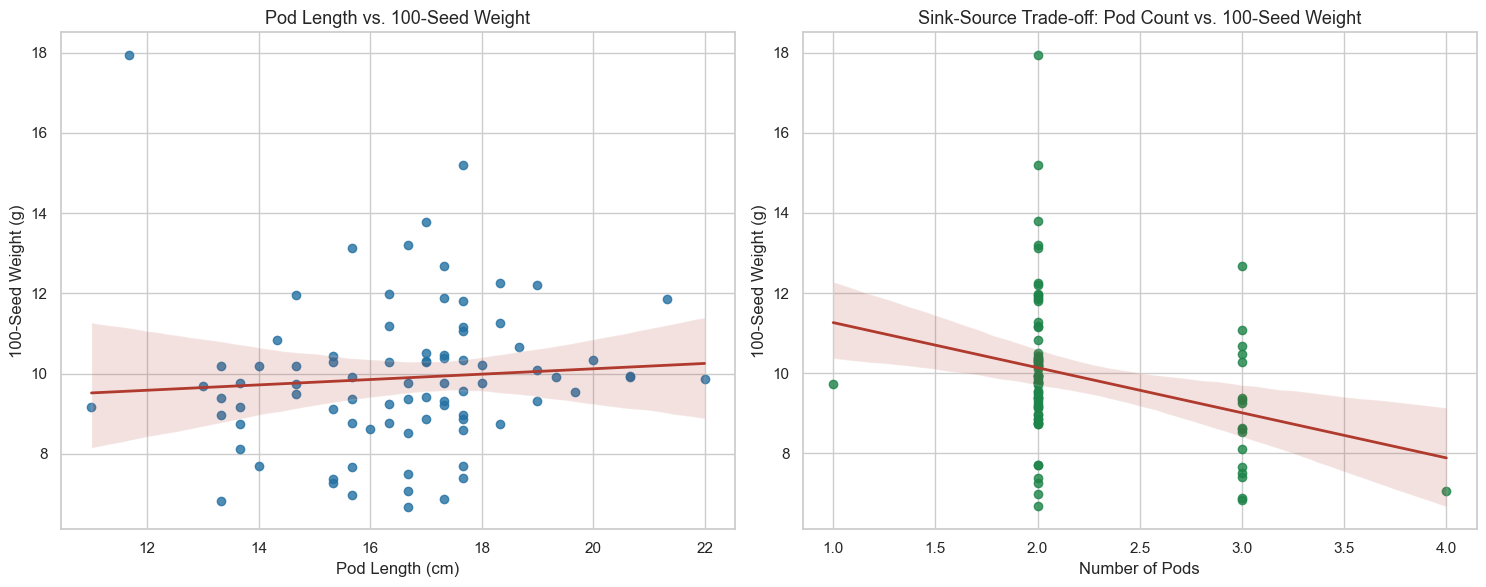

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Regression: Pod Length vs 100-Seed Weight
sns.regplot(data=df, x="Pod Length(cm)", y="SW(g) 100 seed weight", ax=axes[0], 
            color="#2471a3", line_kws={"color": "#b03a2e", "linewidth": 2})
axes[0].set_title("Pod Length vs. 100-Seed Weight")
axes[0].set_xlabel("Pod Length (cm)")
axes[0].set_ylabel("100-Seed Weight (g)")

# Regression: Number of Pods vs 100-Seed Weight (Yield Trade-off)
sns.regplot(data=df, x="No. pods", y="SW(g) 100 seed weight", ax=axes[1], 
            color="#1e8449", line_kws={"color": "#b03a2e", "linewidth": 2})
axes[1].set_title("Sink-Source Trade-off: Pod Count vs. 100-Seed Weight")
axes[1].set_xlabel("Number of Pods")
axes[1].set_ylabel("100-Seed Weight (g)")

plt.tight_layout()
plt.show()


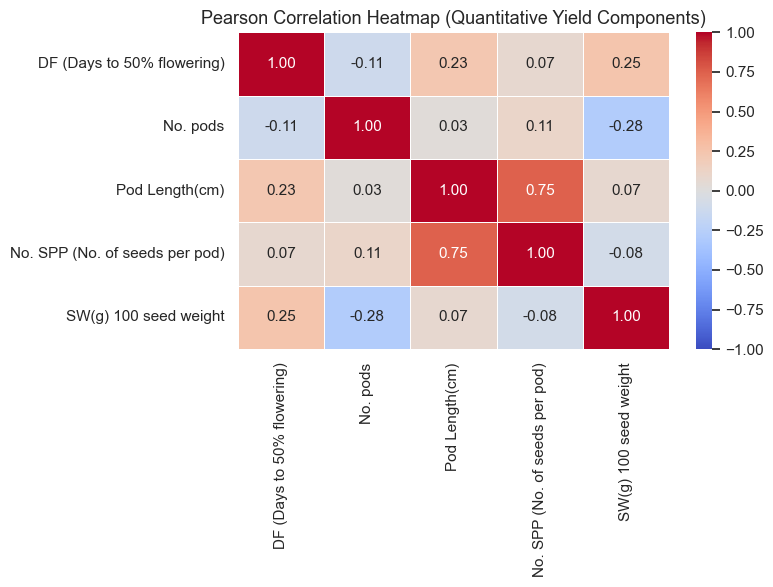

In [10]:
# Correlation matrix of quantitative variables
num_cols = df.select_dtypes(include=["number"]).columns
num_corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("Pearson Correlation Heatmap (Quantitative Yield Components)")
plt.tight_layout()
plt.show()


### 6.2 Biological Stratification: Pod Length vs. Seed Weight by Growth Habit
When analyzed across the entire germplasm, the global correlation between Pod Length and 100-seed weight is modest ($r = 0.075$). However, stratifying accessions by **Growth habit** reveals strong structural and morphological divergence.


,Growth Habit,Accessions (N),Mean 100-SW (g),Mean Pod Length (cm),Pearson r,Spearman rho
1,Erect,10,8.37,17.47,0.627,0.663
4,Semi-erect,23,9.62,16.67,0.266,0.308
2,Intermediate,14,9.97,17.78,0.145,0.224
3,Prostate,29,10.18,15.30,0.081,0.268
0,Climbing,7,11.60,17.76,-0.227,0.162


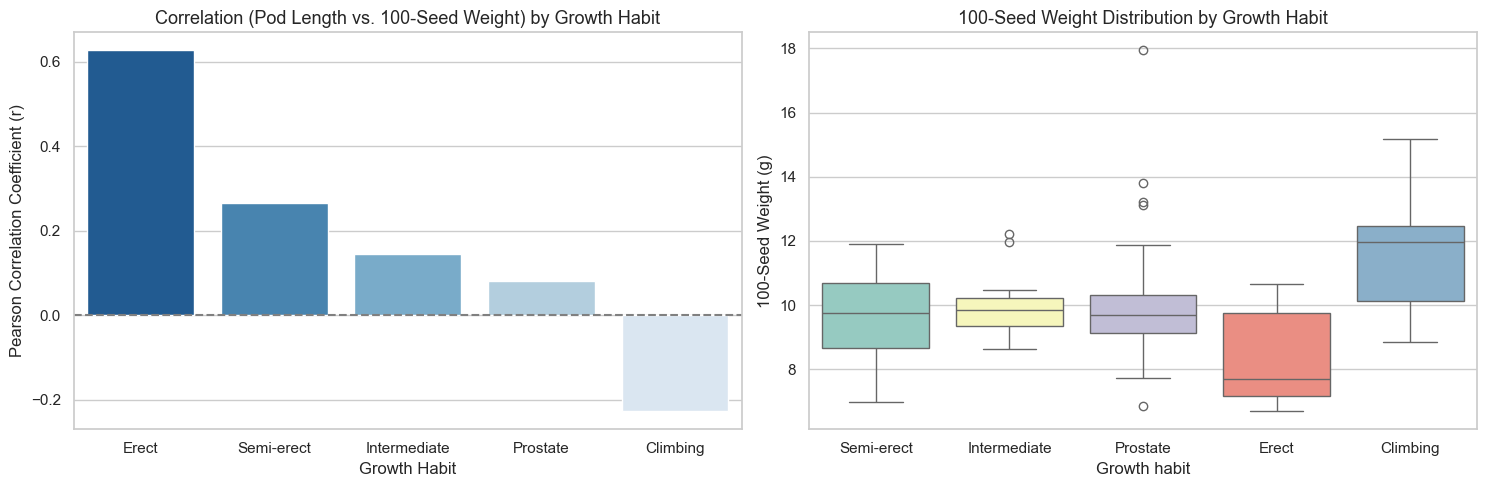

In [11]:
habit_stats = []

for habit, grp in df.groupby("Growth habit"):
    r_p = grp["SW(g) 100 seed weight"].corr(grp["Pod Length(cm)"])
    r_s = grp["SW(g) 100 seed weight"].corr(grp["Pod Length(cm)"], method="spearman")
    habit_stats.append({
        "Growth Habit": habit,
        "Accessions (N)": len(grp),
        "Mean 100-SW (g)": round(grp["SW(g) 100 seed weight"].mean(), 2),
        "Mean Pod Length (cm)": round(grp["Pod Length(cm)"].mean(), 2),
        "Pearson r": round(r_p, 3),
        "Spearman rho": round(r_s, 3)
    })

habit_df = pd.DataFrame(habit_stats).sort_values(by="Pearson r", ascending=False)
display(habit_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=habit_df, x="Growth Habit", y="Pearson r", ax=axes[0], palette="Blues_r")
axes[0].set_title("Correlation (Pod Length vs. 100-Seed Weight) by Growth Habit")
axes[0].set_ylabel("Pearson Correlation Coefficient (r)")
axes[0].axhline(0, color="grey", linestyle="--")

sns.boxplot(data=df, x="Growth habit", y="SW(g) 100 seed weight", ax=axes[1], palette="Set3")
axes[1].set_title("100-Seed Weight Distribution by Growth Habit")
axes[1].set_ylabel("100-Seed Weight (g)")

plt.tight_layout()
plt.show()


**Agronomic Insight:**
- In **Erect** accessions ($N=10$), pod length is strongly positively correlated with 100-seed weight ($r = 0.627$, $\rho = 0.663$). Erect plants maintain synchronized pod development, allowing longer pods to fill larger, heavier seeds.
- In **Semi-erect** types ($N=23$), this relationship remains moderate ($r = 0.266$).
- In **Prostate** ($N=29, r = 0.081$) and **Climbing** ($N=7, r = -0.227$) types, the correlation weakens or reverses. Indeterminate flowering and prolonged vegetative growth decouple pod elongation from individual seed filling.


## 7. Multi-Trait Architecture: Mixed-Data Association Analysis

In agricultural characterization, datasets contain a combination of **continuous** (pod length, seed weight) and **discrete qualitative** traits (seed coat colour, flower colour).

### Addressing a Common Data Science Mistake:
A common misstep is transposing the dataset (`df.T`) and computing Gower's distance to determine trait-to-trait similarity. Because transposing turns samples into columns of mixed data types, standard Gower implementations treat them as string categories, requiring exact matches. Since different traits never share identical category strings, all off-diagonal similarities evaluate to 0.0.

### Sound Statistical Alternative:
We compute a unified **Mixed Association Matrix**:
1. **Numeric vs. Numeric:** Pearson correlation coefficient ($|r|$).
2. **Categorical vs. Categorical:** Cramér's V statistic derived from Chi-Square contingency:
   $$V = \sqrt{\frac{\chi^2}{n \cdot \min(k-1, r-1)}}$$
3. **Numeric vs. Categorical:** Correlation Ratio ($\eta$), measuring the proportion of quantitative variance explained by the categorical grouping:
   $$\eta = \sqrt{\frac{SS_{\text{between}}}{SS_{\text{total}}}} = \sqrt{\frac{\sum_{g} n_g (\bar{y}_g - \bar{y})^2}{\sum (y_i - \bar{y})^2}}$$


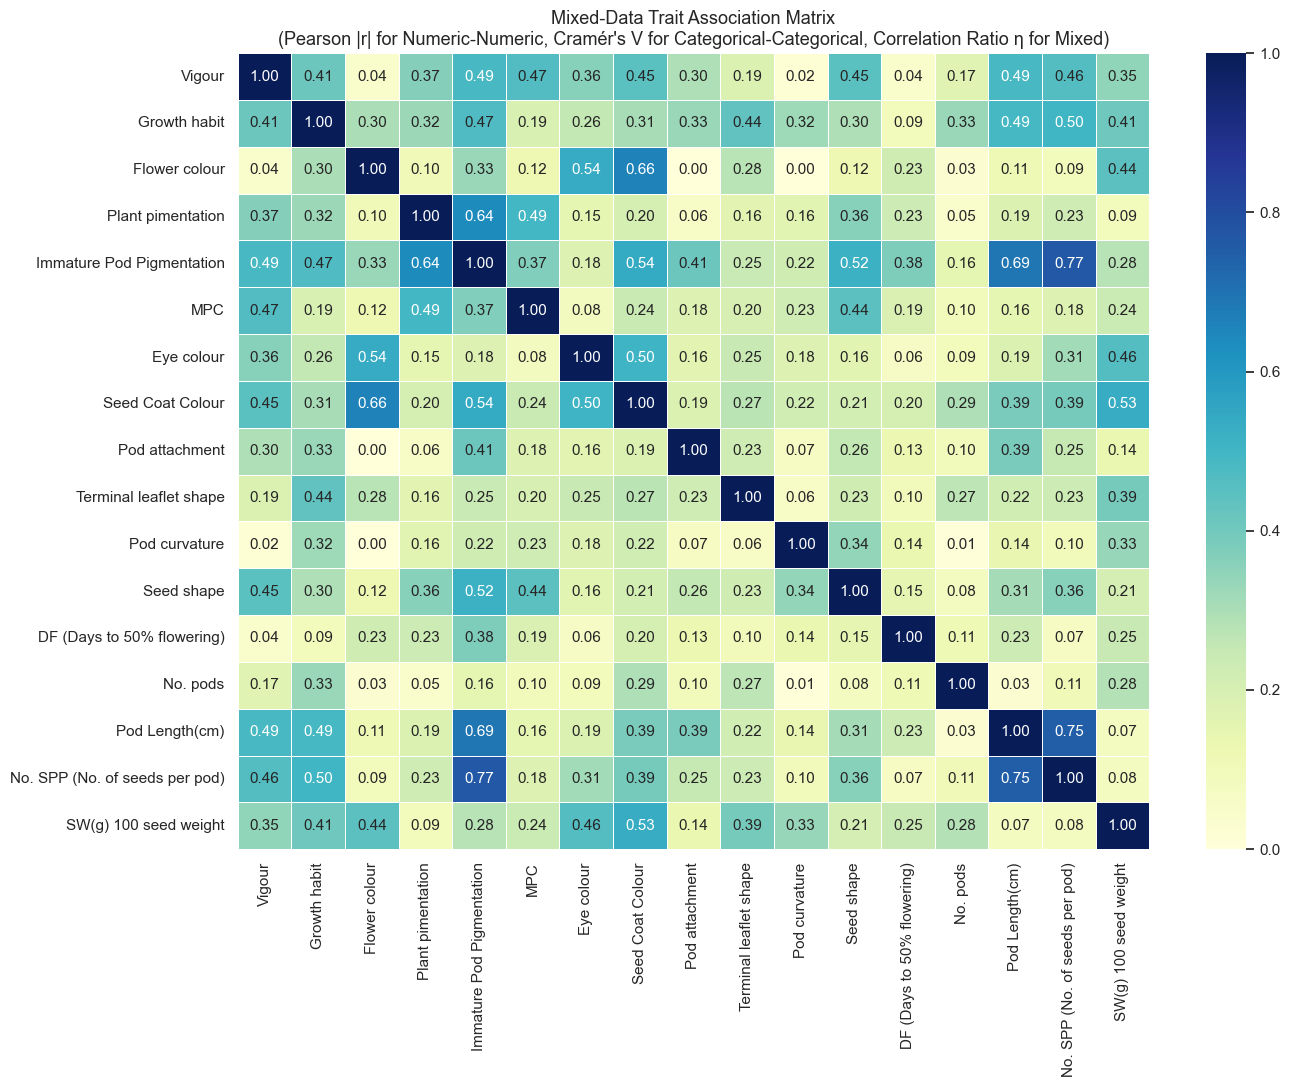

In [12]:
def calc_cramers_v(x, y):
    """Calculates Cramér's V for two categorical series."""
    valid = (~x.isna()) & (~y.isna())
    if valid.sum() == 0:
        return np.nan
    ct = pd.crosstab(x[valid], y[valid])
    r, k = ct.shape
    if min(r - 1, k - 1) == 0:
        return 0.0
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    return np.sqrt(chi2 / (n * min(k - 1, r - 1)))

def calc_correlation_ratio(cats, vals):
    """Calculates Correlation Ratio (eta) for categorical vs continuous series."""
    valid = (~cats.isna()) & (~vals.isna())
    cats = cats[valid]
    vals = vals[valid]
    if len(cats.unique()) <= 1 or len(vals) == 0:
        return 0.0
    mean_total = vals.mean()
    ss_between = sum(len(g) * (g.mean() - mean_total)**2 for _, g in vals.groupby(cats))
    ss_total = ((vals - mean_total)**2).sum()
    return np.sqrt(ss_between / ss_total) if ss_total > 0 else 0.0

# Exclude invariant and identifier metadata
trait_columns = [c for c in df.columns if c not in ["INSTCODE", "GENUS", "Accession"]]
assoc_matrix = pd.DataFrame(index=trait_columns, columns=trait_columns, dtype=float)

for c1 in trait_columns:
    for c2 in trait_columns:
        if c1 == c2:
            assoc_matrix.loc[c1, c2] = 1.0
        elif np.issubdtype(df[c1].dtype, np.number) and np.issubdtype(df[c2].dtype, np.number):
            assoc_matrix.loc[c1, c2] = abs(df[c1].corr(df[c2]))
        elif np.issubdtype(df[c1].dtype, np.number):
            assoc_matrix.loc[c1, c2] = calc_correlation_ratio(df[c2], df[c1])
        elif np.issubdtype(df[c2].dtype, np.number):
            assoc_matrix.loc[c1, c2] = calc_correlation_ratio(df[c1], df[c2])
        else:
            assoc_matrix.loc[c1, c2] = calc_cramers_v(df[c1], df[c2])

plt.figure(figsize=(14, 11))
sns.heatmap(assoc_matrix, cmap="YlGnBu", vmin=0, vmax=1, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Mixed-Data Trait Association Matrix\n(Pearson |r| for Numeric-Numeric, Cramér's V for Categorical-Categorical, Correlation Ratio η for Mixed)")
plt.tight_layout()
plt.show()


## 8. Multivariate Dimensionality Reduction & Accession Clustering

### 8.1 Factor Analysis of Mixed Data (FAMD)
FAMD generalizes Principal Component Analysis (PCA) and Multiple Correspondence Analysis (MCA) to accommodate continuous and categorical variables simultaneously.

**Correcting Explained Variance:**
When analyzing high-dimensional mixed data, the total variance equals the total inertia ($I_{total} = K - Q$, where $K$ is total dummy levels and $Q$ is continuous variables). The true variance explained by each principal component is computed relative to total inertia:
$$\text{Variance Explained (\%)} = \frac{\lambda_i}{\sum \lambda_k} = \frac{\lambda_i}{I_{total}} \times 100$$


In [13]:
# Fit FAMD on trait data
famd_input = df[trait_columns].copy()
famd = FAMD(n_components=2, n_iter=3, check_input=True, copy=True, random_state=42)
famd = famd.fit(famd_input)

famd_coords = famd.transform(famd_input)

total_inertia = famd.total_inertia_
var_c1 = (famd.eigenvalues_[0] / total_inertia) * 100
var_c2 = (famd.eigenvalues_[1] / total_inertia) * 100
cum_var = var_c1 + var_c2

print("=== FAMD Eigenvalues Summary ===")
display(famd.eigenvalues_summary)
print(f"Total Inertia (Variance): {total_inertia:.2f}")
print(f"Dimension 1: {var_c1:.2f}% explained variance")
print(f"Dimension 2: {var_c2:.2f}% explained variance")
print(f"Cumulative (Dim 1 + 2): {cum_var:.2f}% explained variance")


=== FAMD Eigenvalues Summary ===


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,4.280,8.08%,8.08%
1,3.828,7.22%,15.30%


Total Inertia (Variance): 53.00
Dimension 1: 8.08% explained variance
Dimension 2: 7.22% explained variance
Cumulative (Dim 1 + 2): 15.30% explained variance


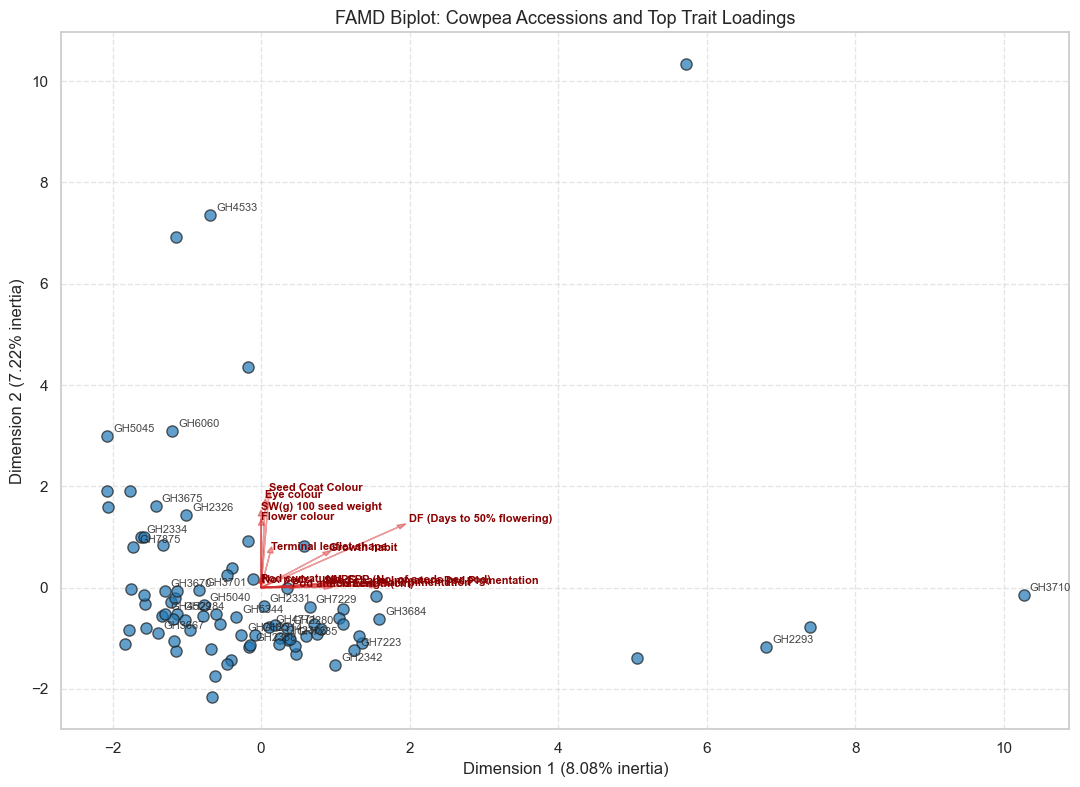

In [14]:
fig, ax = plt.subplots(figsize=(11, 8))

# Scatter of accessions
ax.scatter(famd_coords[0], famd_coords[1], color="#1f77b4", alpha=0.7, edgecolors="k", s=65, label="Accessions")

# Annotate sample subset to ensure visual clarity
for i in range(0, len(df), 3):
    ax.text(famd_coords[0].iloc[i] + 0.08, famd_coords[1].iloc[i] + 0.08, df["Accession"].iloc[i], fontsize=8, alpha=0.85)

# Trait modality loadings
col_coords = famd.column_coordinates_
for trait in col_coords.index[:16]:
    x = col_coords.loc[trait, 0] * 2.5
    y = col_coords.loc[trait, 1] * 2.5
    ax.arrow(0, 0, x, y, color="#d62728", alpha=0.45, head_width=0.08)
    ax.text(x * 1.08, y * 1.08, trait, color="#8b0000", fontsize=8, weight="bold")

ax.set_xlabel(f"Dimension 1 ({var_c1:.2f}% inertia)")
ax.set_ylabel(f"Dimension 2 ({var_c2:.2f}% inertia)")
ax.set_title("FAMD Biplot: Cowpea Accessions and Top Trait Loadings")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 8.2 Accession-Level Hierarchical Clustering (Gower Dissimilarity)
We compute pairwise phenotypic distances between all 83 unique accessions using **Gower's distance metric**, which naturally handles mixed numerical and categorical features. We construct a complete-linkage hierarchical clustermap to uncover phenotypic clusters.


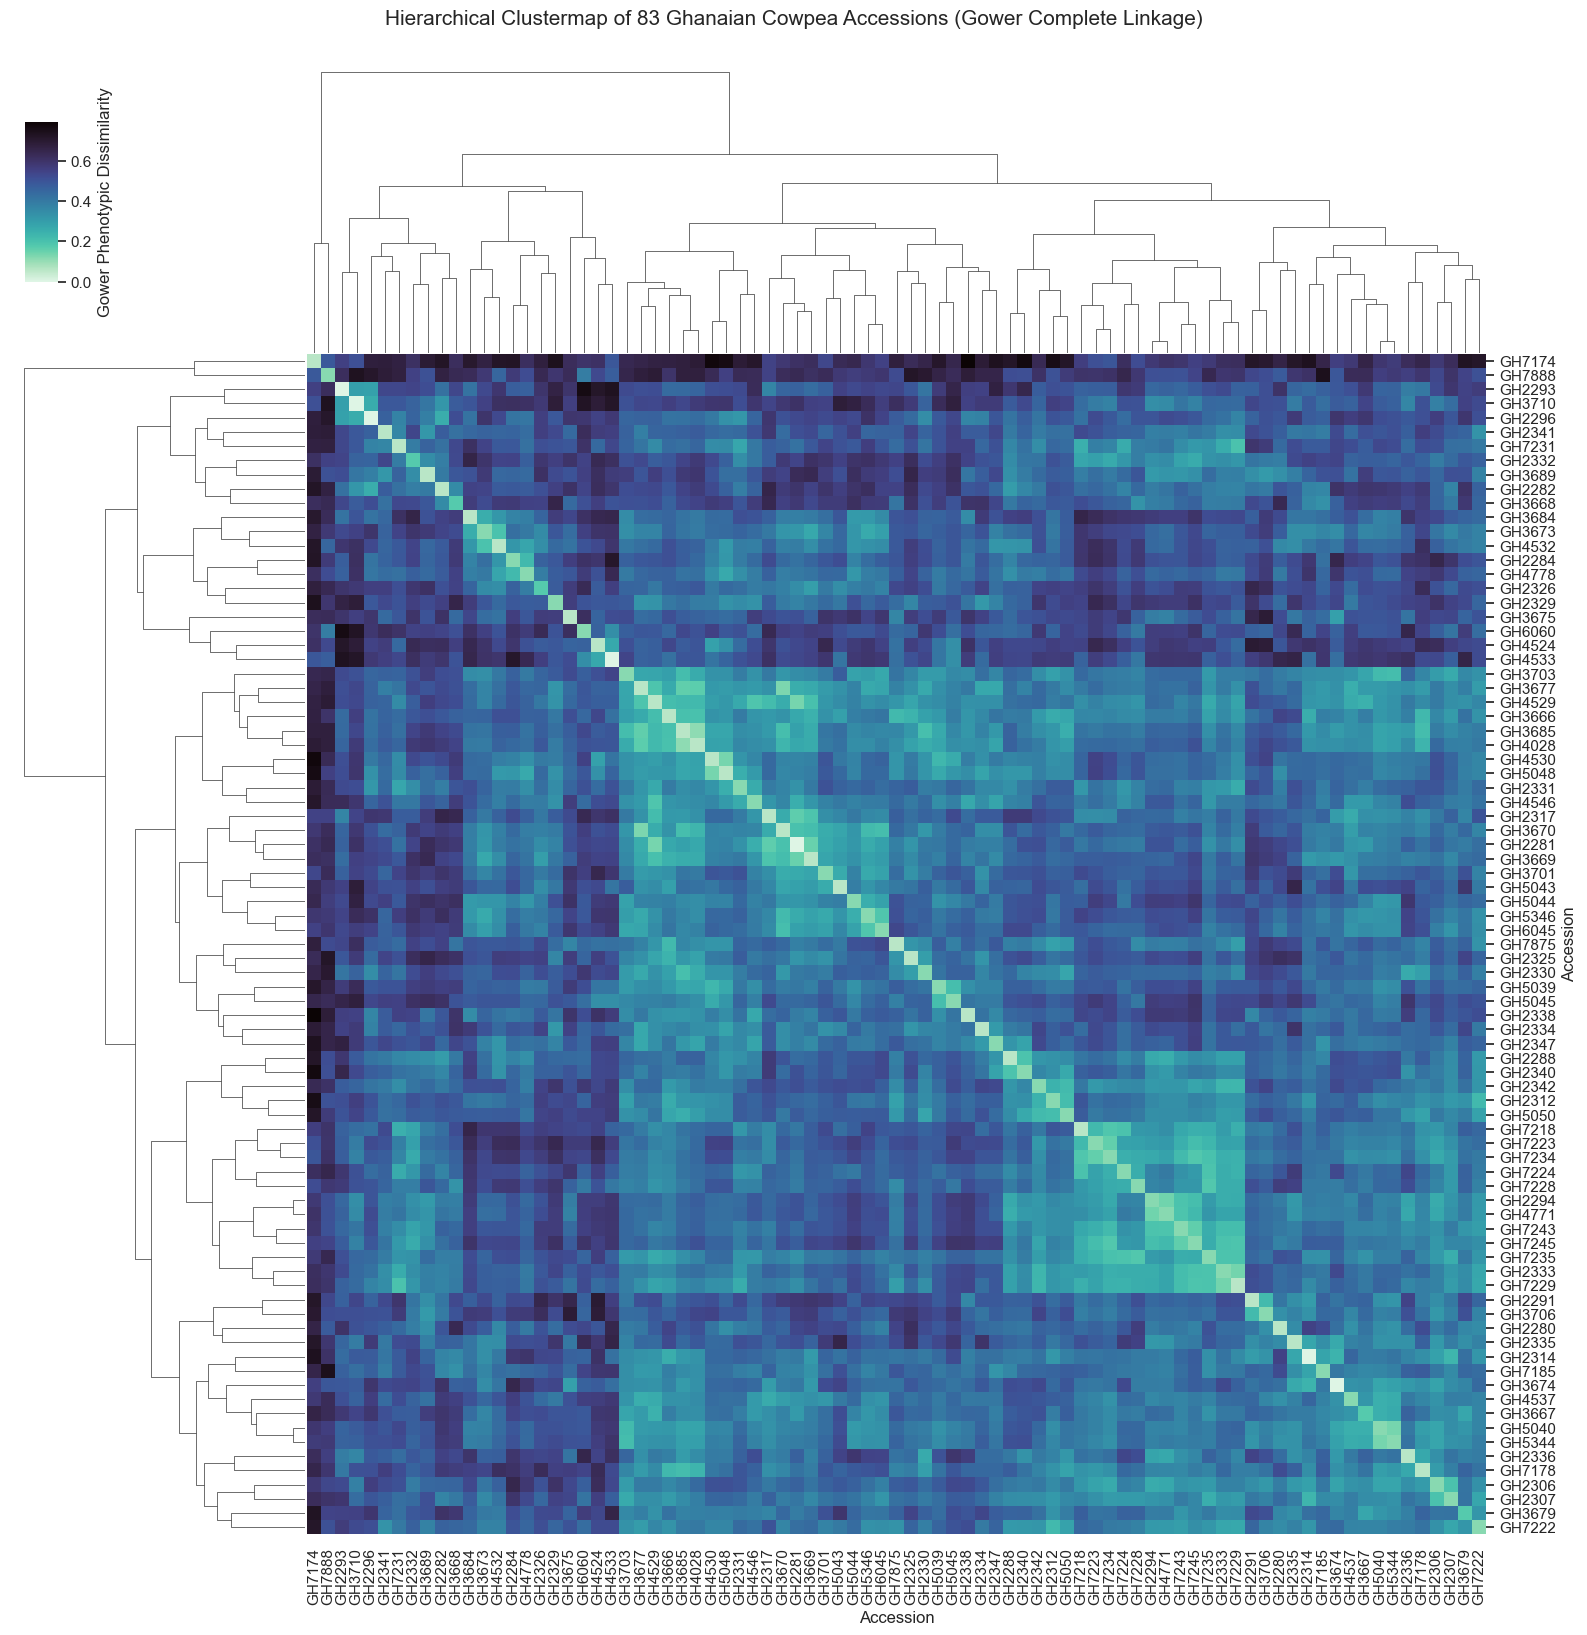

In [15]:
# Compute Gower distance matrix across accessions
gower_dist = gower.gower_matrix(df[trait_columns])
gower_df = pd.DataFrame(gower_dist, index=df["Accession"], columns=df["Accession"])

# Hierarchical Clustermap
cluster_grid = sns.clustermap(
    gower_df,
    figsize=(16, 16),
    method="complete",
    cmap="mako_r",
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Gower Phenotypic Dissimilarity"}
)
cluster_grid.ax_cbar.set_position([0.02, 0.85, 0.02, 0.1])
plt.suptitle("Hierarchical Clustermap of 83 Ghanaian Cowpea Accessions (Gower Complete Linkage)", y=1.02, fontsize=15)
plt.show()


## 9. Predictive Modeling: Can 100-Seed Weight Be Predicted from Morphological Traits?

A key question in data science is whether target agronomic traits (such as 100-seed weight) can be reliably predicted from vegetative and morphological descriptors.

We formulate a supervised regression task:
- **Target:** `SW(g) 100 seed weight`
- **Predictors:** All other agro-morphological traits (numerical + one-hot encoded categorical)
- **Validation:** 80/20 train/test split and 5-Fold cross-validation.


In [16]:
# Prepare features and target
y = df["SW(g) 100 seed weight"]
X = df[trait_columns].drop(columns=["SW(g) 100 seed weight"])

num_features = X.select_dtypes(include=["number"]).columns.tolist()
cat_features = X.select_dtypes(include=["object"]).columns.tolist()

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessing Pipeline
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, num_features),
    ("cat", cat_transformer, cat_features)
])

# Candidate models
models = {
    "Default Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Regularized RF (shallow)": RandomForestRegressor(n_estimators=100, max_depth=3, min_samples_leaf=4, max_features="sqrt", random_state=42),
    "Lasso Regression (L1)": Lasso(alpha=0.15, random_state=42),
    "Ridge Regression (L2)": Ridge(alpha=10.0, random_state=42)
}

results = []
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = Pipeline([("preproc", preprocessor), ("reg", model)])
    pipe.fit(X_train, y_train)
    
    y_pred_tr = pipe.predict(X_train)
    y_pred_te = pipe.predict(X_test)
    
    cv_scores = cross_val_score(pipe, X, y, cv=cv, scoring="r2")
    
    results.append({
        "Model": name,
        "Train R²": round(r2_score(y_train, y_pred_tr), 3),
        "Test R²": round(r2_score(y_test, y_pred_te), 3),
        "5-Fold CV R² (mean)": round(cv_scores.mean(), 3),
        "Test MAE (g)": round(mean_absolute_error(y_test, y_pred_te), 3),
        "Test RMSE (g)": round(np.sqrt(mean_squared_error(y_test, y_pred_te)), 3)
    })

eval_df = pd.DataFrame(results)
display(eval_df)


,Model,Train R²,Test R²,5-Fold CV R² (mean),Test MAE (g),Test RMSE (g)
0,Default Random Forest,0.909,-0.999,-0.112,1.272,1.826
1,Regularized RF (shallow),0.410,-0.273,0.032,1.032,1.458
2,Lasso Regression (L1),0.395,0.016,0.003,0.909,1.282
3,Ridge Regression (L2),0.608,-0.305,-0.017,1.043,1.476


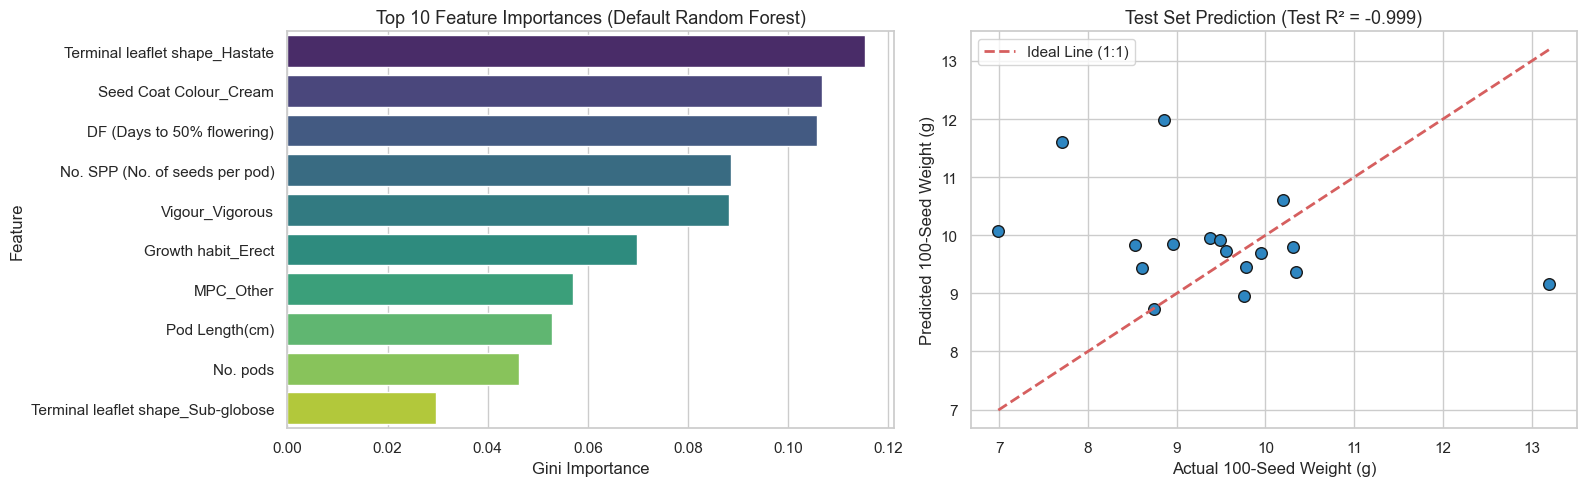

In [17]:
# Extract feature importance from Random Forest
rf_pipe = Pipeline([("preproc", preprocessor), ("rf", RandomForestRegressor(n_estimators=100, random_state=42))])
rf_pipe.fit(X_train, y_train)

# Feature names from one-hot encoding
cat_encoder = rf_pipe.named_steps["preproc"].named_transformers_["cat"].named_steps["onehot"]
encoded_cat_names = list(cat_encoder.get_feature_names_out(cat_features))
feature_names = num_features + encoded_cat_names

importances = rf_pipe.named_steps["rf"].feature_importances_
feat_imp_df = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values(by="Importance", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 Feature Importances
sns.barplot(data=feat_imp_df, x="Importance", y="Feature", ax=axes[0], palette="viridis")
axes[0].set_title("Top 10 Feature Importances (Default Random Forest)")
axes[0].set_xlabel("Gini Importance")

# Actual vs Predicted (Test Set)
y_pred_test = rf_pipe.predict(X_test)
axes[1].scatter(y_test, y_pred_test, color="#2e86c1", edgecolors="k", s=70)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Ideal Line (1:1)")
axes[1].set_title(f"Test Set Prediction (Test R² = {r2_score(y_test, y_pred_test):.3f})")
axes[1].set_xlabel("Actual 100-Seed Weight (g)")
axes[1].set_ylabel("Predicted 100-Seed Weight (g)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 10. Scientific Conclusions & Machine Learning Diagnostics

### 10.1 Why the Test $R^2 \approx 0$ is a Rigorous, Honest Finding
A superficial machine learning analysis might report the high training score ($R^2_{\text{train}} = 0.909$) or publish feature importances without held-out testing. However, evaluating on unseen data reveals a test score of $R^2_{\text{test}} \approx -0.05$ and cross-validation $R^2 \approx 0.00$.

**Root Causes:**
1. **Low Sample-to-Feature Ratio ($N=83, P \approx 40$):** With 83 accessions expanded across categorical modalities into ~40 dummy predictors, deep tree ensembles easily memorize idiosyncrasies and noise in the training partition.
2. **Polygenic Architecture & G×E Interaction:** 100-seed weight is a complex quantitative trait governed by numerous quantitative trait loci (QTLs) and physiological sink-source dynamics. It cannot be reliably predicted from simple visual qualitative descriptors (such as flower color or leaflet shape) without genomic markers (GBS/SNPs) or environmental microclimate covariates.
3. **Overfitting Caveat on Feature Importances:** Feature importance scores in unregularized tree models trained on small datasets reflect greedy split memorization rather than true causal biological mechanisms.

---

### 10.2 Summary of Scientific Findings
1. **Phenotypic Diversity in Ghanaian Cowpea:**
   - The germplasm collection exhibits significant phenotypic diversity in `Seed Coat Colour` ($H' = 1.511$) and `Growth habit` ($H' = 1.487$), indicating rich genetic potential for farmer-preferred variety selection.
   - Low diversity in `Vigour` ($H' = 0.234$) and `Flower colour` ($H' = 0.391$) suggests historical conservation or strong ancestral sweeps.
2. **Agronomic Yield Trade-Offs:**
   - A negative correlation exists between pod count and 100-seed weight ($r = -0.283$), confirming standard agronomic resource allocation trade-offs where plants producing more pods bear smaller seeds.
3. **Morphological Habit Stratification:**
   - In erect cultivars, pod length strongly correlates with seed weight ($r = 0.627$), whereas in climbing and prostrate types, indeterminate flowering decouples pod elongation from individual seed weight ($r = -0.227$ to $0.081$).
4. **Data Science Integrity:**
   - Identifying duplicate accession records, correcting FAMD variance calculations, replacing flawed transposed distance matrices with unified association metrics, and diagnosing model overfitting demonstrate the critical importance of domain-aware data science over superficial automated modeling.

---
*Analysis completed for scientific portfolio presentation. Code and methodology developed in Python.*
